##Seguimiento de múltiples objetos con Ultralytics YOLO#


In [ ]:
!pip install -q ultralytics

import ultralytics
ultralytics.checks()

from ultralytics import YOLO
import torch



Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.7/235.7 GB disk)


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

# Default tracker (TrackTrack)
#results = model.track(source="https://www.youtube.com/watch?v=tOzCoDvRqyk", show=True, save=True)

# Switch to ByteTrack
results = model.track(source="https://www.youtube.com/watch?v=DWgfWOHXDY8&source_ve_path=OTY3MTQ&embeds_referring_euri=https%3A%2F%2Fmx.video.search.yahoo.com%2F&embeds_referring_origin=https%3A%2F%2Fmx.video.search.yahoo.com", show=True, tracker="bytetrack.yaml", save=True)

WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()


1/1: https://www.youtube.com/watch?v=DWgfWOHXDY8&source_ve_path=OTY3MTQ&embeds_referring_euri=https%3A%2F%2Fmx.video.search.yahoo.com%2F&embeds_referring_origin=https%3A%2F%2Fmx.video.search.yahoo.com... Success ✅ (3640 frames of shape 1920x1080 at 30.00 FPS)

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

0: 384x640 5 persons, 7 cars, 1 motorcycle, 4 trucks, 10.8ms
0: 384x640 1 person, 11.4ms
0: 384x640 2 persons, 13.9ms
0: 384

In [ ]:
model = YOLO("yolo26n.pt")

# Default tracker (TrackTrack)
results = model.track(source="https://www.youtube.com/watch?v=vqqt5p0q-eU", show=True)

# Switch to ByteTrack
#results = model.track(source="https://www.youtube.com/watch?v=FzRGSlhQIyY", show=True, tracker="bytetrack.yaml")


1/1: https://www.youtube.com/watch?v=vqqt5p0q-eU... Success ✅ (780 frames of shape 1920x1080 at 29.97 FPS)

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

0: 384x640 2 persons, 16.5ms
0: 384x640 2 persons, 18.7ms
0: 384x640 2 persons, 36.0ms
0: 384x640 2 persons, 34.8ms
0: 384x640 2 persons, 48.1ms
0: 384x640 2 persons, 57.0ms
0: 384x640 2 persons, 27.0ms
0: 384x640 2 persons, 26.0ms
0: 384x640 2 persons, 52.1ms
0: 384x640 1 person, 53.5ms
0: 384x640 1 person, 79.6ms
0: 384x640 1 person, 59.2ms
0: 384

In [ ]:

results = model.track(source="https://www.youtube.com/watch?v=MiN_kgpkn-U", conf=0.1, iou=0.7, show=True, save=True)


1/1: https://www.youtube.com/watch?v=MiN_kgpkn-U... Success ✅ (1573 frames of shape 1920x1080 at 29.00 FPS)

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

0: 384x640 3 persons, 26.6ms
0: 384x640 1 person, 26.5ms
0: 384x640 19 persons, 4 cars, 2 trucks, 1 umbrella, 7 handbags, 28.4ms
0: 384x640 1 person, 19.0ms
0: 384x640 1 person, 16.0ms
0: 384x640 1 person, 14.3ms
0: 384x640 3 persons, 15.7ms
0: 384x640 3 persons, 1 umbrella, 15.0ms
0: 384x640 3 persons, 17.5ms
0: 384x640 3 persons, 14.0ms
0: 384x64

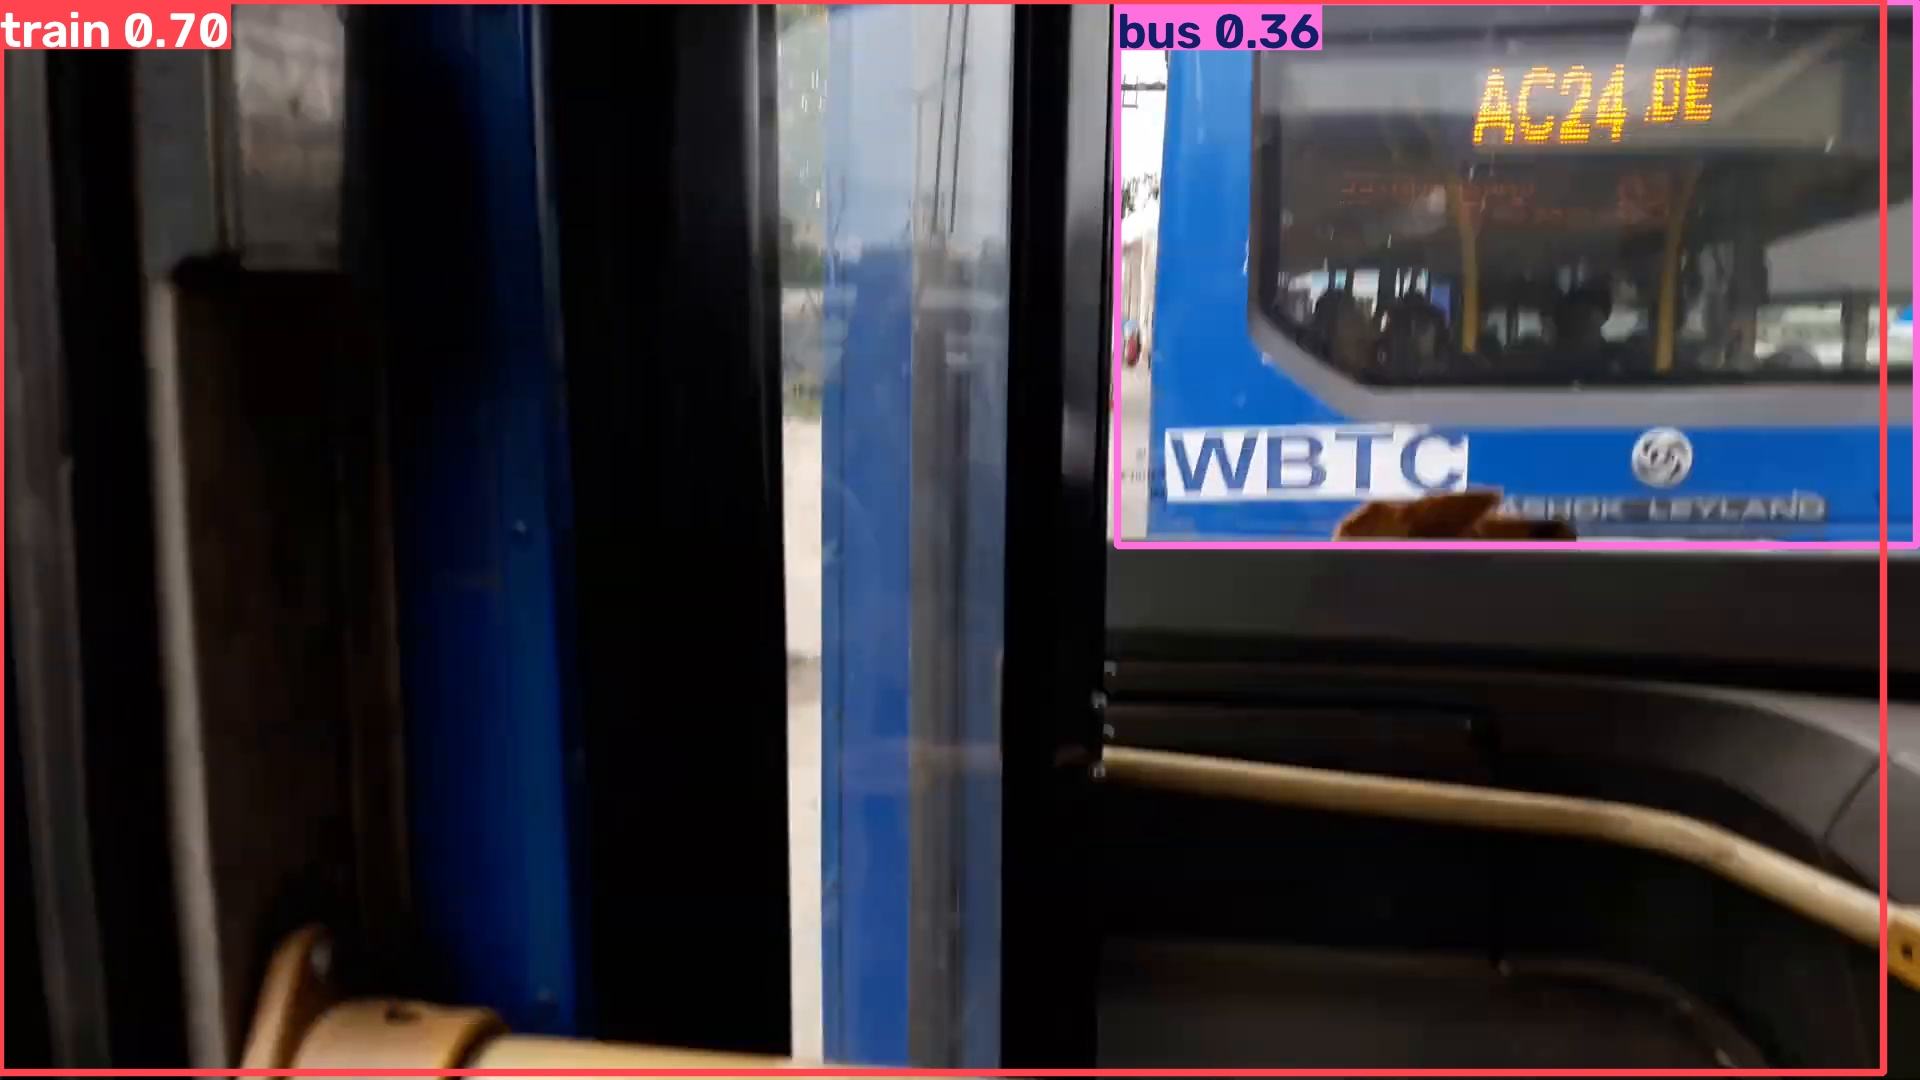

In [ ]:
import cv2
from IPython.display import display, Image, clear_output

for i, r in enumerate(results):
    frame_annotated = r.plot()

    if i % 10 == 0:
        clear_output(wait=True)
        _, buffer = cv2.imencode('.jpg', frame_annotated)
        display(Image(data=buffer.tobytes()))

##Camara

In [ ]:
from base64 import b64decode, b64encode
from google.colab.output import eval_js
from IPython.display import display, Javascript
from PIL import Image
import io
import numpy as np

IMG_SHAPE = [640, 480]*2
IMG_QUALITY = 0.8

def start_stream():
    js = Javascript(f'''
    const IMG_SHAPE = {IMG_SHAPE};
    const IMG_QUALITY = {IMG_QUALITY};
    ''' + '''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;
    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
        stream.getVideoTracks()[0].stop();
        video.remove();
        div.remove();
        video = null; div = null; stream = null;
        imgElement = null; captureCanvas = null; labelElement = null;
    }

    function onAnimationFrame() {
        if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
        if (pendingResolve) {
            var result = "";
            if (!shutdown) {
                captureCanvas.getContext('2d').drawImage(video, 0, 0, IMG_SHAPE[0], IMG_SHAPE[1]);
                result = captureCanvas.toDataURL('image/jpeg', IMG_QUALITY);
            }
            var lp = pendingResolve;
            pendingResolve = null;
            lp(result);
        }
    }

    async function createDom() {
        if (div !== null) { return stream; }
        div = document.createElement('div');
        div.style.border = '2px solid black';
        div.style.padding = '3px';
        div.style.width = '100%';
        div.style.maxWidth = '600px';
        document.body.appendChild(div);

        const modelOut = document.createElement('div');
        modelOut.innerHTML = "<span>Estado: </span>";
        labelElement = document.createElement('span');
        labelElement.innerText = 'Sin datos';
        labelElement.style.fontWeight = 'bold';
        modelOut.appendChild(labelElement);
        div.appendChild(modelOut);

        video = document.createElement('video');
        video.style.display = 'block';
        video.width = div.clientWidth - 6;
        video.setAttribute('playsinline', '');
        video.onclick = () => { shutdown = true; };
        stream = await navigator.mediaDevices.getUserMedia({video: { facingMode: "environment"}});
        div.appendChild(video);

        imgElement = document.createElement('img');
        imgElement.style.position = 'absolute';
        imgElement.style.zIndex = 1;
        imgElement.onclick = () => { shutdown = true; };
        div.appendChild(imgElement);

        const instruction = document.createElement('div');
        instruction.innerHTML = '<span style="color: red; font-weight: bold;">Al terminar, den clic aquí o en el video para detener</span>';
        div.appendChild(instruction);
        instruction.onclick = () => { shutdown = true; };

        video.srcObject = stream;
        await video.play();

        captureCanvas = document.createElement('canvas');
        captureCanvas.width = IMG_SHAPE[0];
        captureCanvas.height = IMG_SHAPE[1];
        window.requestAnimationFrame(onAnimationFrame);
        return stream;
    }

    async function takePhoto(label, imgData) {
        if (shutdown) { removeDom(); shutdown = false; return ''; }
        stream = await createDom();
        if (label != "") { labelElement.innerHTML = label; }
        if (imgData != "") {
            var videoRect = video.getClientRects()[0];
            imgElement.style.top = videoRect.top + "px";
            imgElement.style.left = videoRect.left + "px";
            imgElement.style.width = videoRect.width + "px";
            imgElement.style.height = videoRect.height + "px";
            imgElement.src = imgData;
        }
        var result = await new Promise((resolve, reject) => pendingResolve = resolve);
        shutdown = false;
        return {'img': result};
    }
    ''')
    display(js)

def take_photo(label, img_data):
    return eval_js(f'takePhoto("{label}", "{img_data}")')

def js_response_to_image(js_response):
    _, b64_str = js_response['img'].split(',')
    return Image.open(io.BytesIO(b64decode(b64_str)))

def black_rgb_canvas(h, w):
    return np.zeros([h, w, 3], dtype=np.uint8)

def hide_black_pixels(rgb_array):
    alpha = (rgb_array.max(axis=2) > 0).astype(np.uint8) * 255
    return np.dstack((rgb_array, alpha))

def draw_annotations_on_transparent_bg(detection_result):
    h, w = detection_result.orig_shape[:2]
    boxes_on_black = detection_result.plot(masks=False, img=black_rgb_canvas(h, w))
    rgba = hide_black_pixels(boxes_on_black)
    return Image.fromarray(rgba)


In [ ]:
start_stream()
modelo_deteccion = YOLO("yolo26n.pt")

img_data = ''
while True:
    js_response = take_photo('Capturando...', img_data)
    if not js_response:
        break
    captured_img = js_response_to_image(js_response)
    for detection_result in modelo_deteccion(source=np.array(captured_img), verbose=False):
        annotations_img = draw_annotations_on_transparent_bg(detection_result)
        with io.BytesIO() as buffer:
            annotations_img.save(buffer, format='png')
            img_as_base64_str = str(b64encode(buffer.getvalue()), 'utf-8')
            img_data = f'data:image/png;base64,{img_as_base64_str}'


<IPython.core.display.Javascript object>